# spread_source 01 — Fire spread: from ISI, wind and slope to isochrones
**Question.** If a fire starts at a known point, where will the front be after 15, 30, 60 minutes?
**Honest scope.** The *form* of the equations is standard (Canadian Fire Behaviour Prediction System, FBP); the *numbers* of the fuel (`a, b, c`) are placeholders, because no Mediterranean fuel calibration exists in this project.
What we can verify is the geometry and the numerics. What we cannot claim is that the predicted times match a real fire.

## 1. Head rate from ISI
`R = a (1 - exp(-b·ISI))^c` (m/min). It increases with ISI and saturates. Placeholder: a = 45, b = 0.05, c = 1.2.

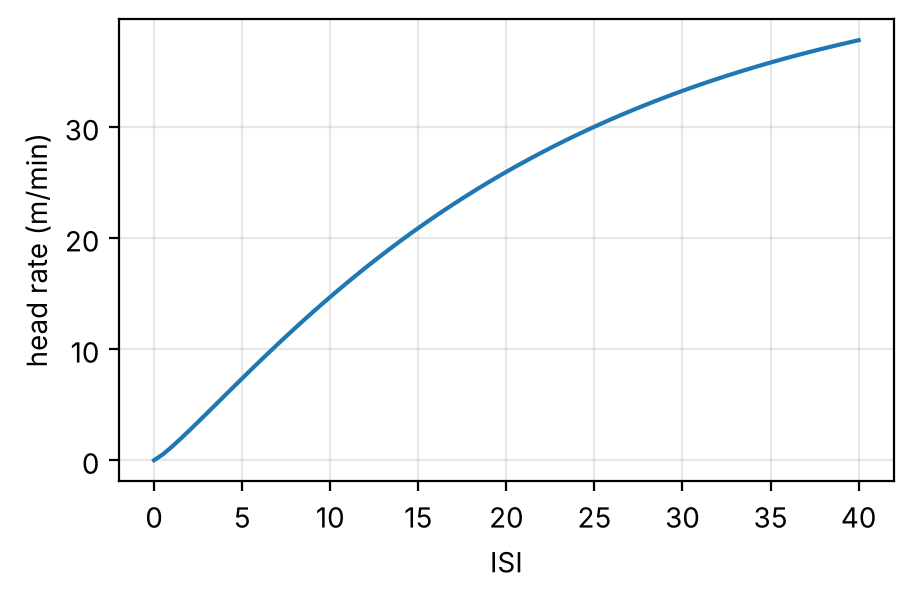

In [1]:
import sys, pathlib, math, time
import numpy as np
import matplotlib.pyplot as plt
ROOT = pathlib.Path.cwd().resolve().parents[1]
sys.path[:0] = [str(ROOT / "python/src"), str(ROOT.parent / "common/python/src")]
from spread_source import FireSpread, head_rate, length_to_breadth
isi = np.linspace(0, 40, 81)
plt.figure(figsize=(5, 3)); plt.plot(isi, [head_rate(x) for x in isi]); plt.xlabel("ISI"); plt.ylabel("head rate (m/min)"); plt.grid(alpha=.3); plt.show()

## 2. Shape of the front: an ellipse with the ignition at a focus
Wind stretches the burn area. The length-to-breadth ratio is `LB = 1 + 8.729 (1 - exp(-0.030 W))^2.155` (W in km/h; form to verify against the primary FBP reference).
For an ellipse of semi-major axis `a`, eccentricity `e` (so `LB = a/b = 1/√(1-e²)`), the ignition sits at a focus. In polar coordinates around that focus, with φ measured from the downwind direction:

`r(φ) = a(1-e²) / (1 - e cos φ)`.

Head (φ = 0): `a(1+e)`; back (φ = π): `a(1-e)`; so with a head rate `R` we have `a = R/(1+e)` and

**`r(φ) = R (1-e) / (1 - e cos φ)`**, back rate `R(1-e)/(1+e)`, flank rate `R(1-e)`.

Because the same `r(φ)` applies at every time, the front at time `t` is the ellipse scaled by `t`. The arrival time at a point at distance `d` in direction φ is `d / r(φ)`.

In [2]:
for w in (0, 8, 15, 25):
    LB = length_to_breadth(w); e = math.sqrt(1 - 1 / LB ** 2)
    print(f"wind {w:2d} km/h: LB {LB:4.2f}  e {e:4.2f}  back/head {(1-e)/(1+e):4.2f}  flank/head {1-e:4.2f}")

wind  0 km/h: LB 1.00  e 0.00  back/head 1.00  flank/head 1.00
wind  8 km/h: LB 1.31  e 0.65  back/head 0.21  flank/head 0.35
wind 15 km/h: LB 1.98  e 0.86  back/head 0.07  flank/head 0.14
wind 25 km/h: LB 3.20  e 0.95  back/head 0.03  flank/head 0.05


## 3. Arrival times on a grid (Dijkstra, 16 neighbours)
The front is propagated from cell to cell; each move costs `distance / r(φ_move)` divided by a slope factor and a fuel factor. 16 neighbours (8 king moves + 8 knight moves) reduce the staircase error of 4- or 8-neighbour grids.
Slope: `exp(±3.533 |s|^1.2)` per edge (FBP form for upslope; the symmetric treatment of downslope and the clipping to [0.2, 5] are **our assumptions**).

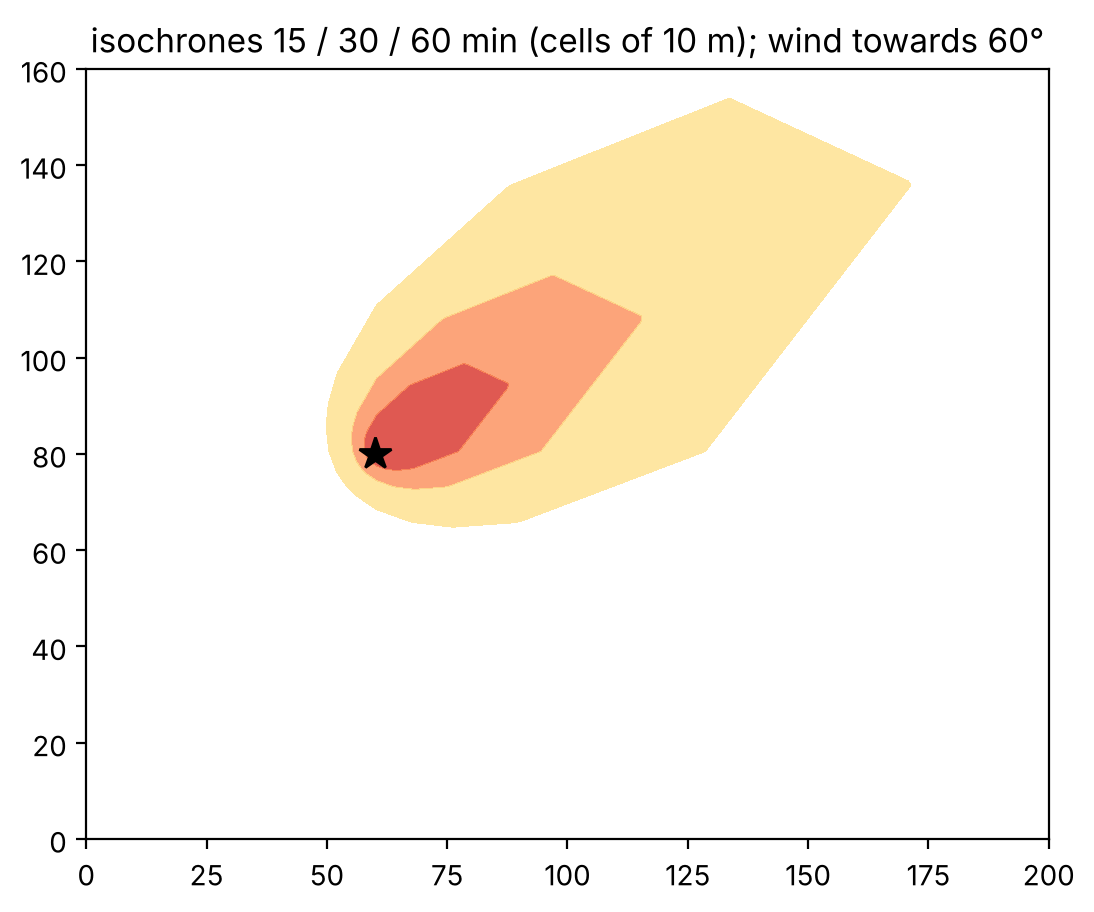

In [3]:
cell = 10.0
fs = FireSpread(160, 200, cell=cell)
ix, iy = 60, 80
arr = fs.arrival((ix, iy), isi=15, wind_kmh=15, wind_to_deg=60)       # wind blows towards ENE
fig, ax = plt.subplots(figsize=(7, 5))
cs = ax.contourf(arr, levels=[0, 15, 30, 60], colors=["#d73027", "#fc8d59", "#fee08b"], extent=(0, 200, 0, 160), alpha=.8)
ax.plot(ix, iy, "k*", ms=12); ax.set_aspect("equal"); ax.set_title("isochrones 15 / 30 / 60 min (cells of 10 m); wind towards 60°"); plt.show()

## 4. Verification against the analytic circle and ellipse (the pass criteria of the fiche)

In [4]:
fs0 = FireSpread(121, 121, cell=10.0)
a0 = fs0.arrival((60, 60), isi=15, wind_kmh=0.0, wind_to_deg=0)
yy, xx = np.mgrid[0:121, 0:121]; d = np.hypot(xx - 60, yy - 60) * 10; m = d > 50
err = np.abs(a0[m] - d[m] / head_rate(15)) / (d[m] / head_rate(15))
print("no wind, flat: mean relative arrival-time error %.2f %%  (criterion <= 4 %%), max %.2f %%" % (100 * err.mean(), 100 * err.max()))

for wind in (8.0, 15.0):
    cell = 5.0; fsw = FireSpread(301, 360, cell=cell); ix, iy, T = 60, 150, 60.0
    aw = fsw.arrival((ix, iy), isi=15, wind_kmh=wind, wind_to_deg=90.0)
    mk = aw <= T; xs = np.where(mk.any(0))[0]; ys = np.where(mk.any(1))[0]
    head, back = (xs.max() - ix) * cell, (ix - xs.min()) * cell
    R, LB = head_rate(15), length_to_breadth(wind); e = math.sqrt(1 - 1 / LB ** 2)
    print(f"wind {wind:4.1f} km/h, T={T:.0f} min: head {head:.0f} m (analytic {R*T:.0f}), back {back:.0f} m (analytic {R*T*(1-e)/(1+e):.0f}), "
          f"L/B {(xs.max()-xs.min())/(ys.max()-ys.min()):.2f} (analytic {LB:.2f})")

no wind, flat: mean relative arrival-time error 1.33 %  (criterion <= 4 %), max 2.75 %


wind  8.0 km/h, T=60 min: head 1250 m (analytic 1254), back 265 m (analytic 268), L/B 1.32 (analytic 1.31)


wind 15.0 km/h, T=60 min: head 1250 m (analytic 1254), back 90 m (analytic 92), L/B 2.00 (analytic 1.98)


## 5. Slope and cost
Uphill is faster than downhill; the run time on a 100 × 100 grid is the spec target (< 1 s).

In [5]:
z = np.tile(np.arange(121) * 4.0, (121, 1))                         # 0.4 rise per 10 m cell step eastwards -> slope 0.4
fsz = FireSpread(121, 121, cell=10.0, elevation=z)
az = fsz.arrival((60, 60), isi=10, wind_kmh=0, wind_to_deg=0)
print("time to 300 m: uphill (east) %.1f min | downhill (west) %.1f min | across slope %.1f min" % (az[60, 90], az[60, 30], az[90, 60]))
t0 = time.perf_counter(); FireSpread(100, 100, cell=20.0).arrival((50, 50), isi=12, wind_kmh=15, wind_to_deg=45)
print("100 x 100 grid, 16 neighbours: %.2f s (cloud CPU; not VIM4)" % (time.perf_counter() - t0))

time to 300 m: uphill (east) 6.3 min | downhill (west) 62.8 min | across slope 20.4 min
100 x 100 grid, 16 neighbours: 0.04 s (cloud CPU; not VIM4)


## What this block does not say
- Nothing here was compared to a real fire perimeter. Fuel numbers are placeholders; wind is constant; no spotting, no suppression, no fuel breaks except via the `fuel` grid.
- The output is a *what-if* for the dashboard ("if ignition is here, then in 30 min…"), not a forecast with a skill score.